# Cryptocurrency Price Forecasting

## HistGradientBoosting Model

### Objective

To build a HistGradientBoosting regression model using engineered cryptocurrency market features and evaluate its performance on an unseen test period.

The model will be trained using historical price, volume, technical indicator, and lag-based features to predict the target cryptocurrency price.

In [3]:
# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)

print("All libraries imported successfully.")

All libraries imported successfully.


In [4]:
# Load cleaned dataset

df = pd.read_csv("../data/engineered_data_cleaned.csv")

print("Cleaned dataset loaded successfully.")
print("Dataset shape:", df.shape)

Cleaned dataset loaded successfully.
Dataset shape: (3011, 18)


In [5]:
# Convert Date to datetime

df["Date"] = pd.to_datetime(df["Date"])

print("Date data type:", df["Date"].dtype)

Date data type: datetime64[us]


In [6]:
# Sort data chronologically

df = df.sort_values("Date").reset_index(drop=True)

print("Data sorted chronologically.")
print("First date:", df["Date"].min())
print("Last date:", df["Date"].max())

Data sorted chronologically.
First date: 2013-12-27 00:00:00
Last date: 2022-10-16 00:00:00


In [7]:
# Check data quality

print("Missing values:", df.isnull().sum().sum())
print("Infinite values:", np.isinf(df.select_dtypes(include=np.number)).sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values: 0
Infinite values: 0
Duplicate rows: 0


In [8]:
# Define features and target

feature_columns = [
    "Open",
    "High",
    "Low",
    "Close",
    "Volume",
    "Return",
    "SMA_7",
    "SMA_14",
    "Volatility_7",
    "RSI_14",
    "MACD",
    "MACD_Signal",
    "Lag_1",
    "Lag_2",
    "Lag_3",
    "Volume_Change"
]

target_column = "Target"

X = df[feature_columns]
y = df[target_column]

print("Number of features:", len(feature_columns))
print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Number of features: 16
Feature shape: (3011, 16)
Target shape: (3011,)


In [9]:
# Chronological train-test split

split_index = int(len(df) * 0.80)

train_df = df.iloc[:split_index].copy()
test_df = df.iloc[split_index:].copy()

print("Training set:", train_df.shape)
print("Testing set:", test_df.shape)

print("\nTraining period:")
print(train_df["Date"].min(), "to", train_df["Date"].max())

print("\nTesting period:")
print(test_df["Date"].min(), "to", test_df["Date"].max())

Training set: (2408, 18)
Testing set: (603, 18)

Training period:
2013-12-27 00:00:00 to 2020-08-04 00:00:00

Testing period:
2020-08-05 00:00:00 to 2022-10-16 00:00:00


In [10]:
# Prepare HistGradientBoosting data

X_train = train_df[feature_columns].copy()
y_train = train_df[target_column].copy()

X_test = test_df[feature_columns].copy()
y_test = test_df[target_column].copy()

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (2408, 16)
y_train: (2408,)
X_test: (603, 16)
y_test: (603,)


In [11]:
# Train baseline HistGradientBoosting model

hgb_model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.1,
    max_leaf_nodes=31,
    l2_regularization=0.0,
    random_state=42
)

hgb_model.fit(X_train, y_train)

print("Baseline HistGradientBoosting model trained successfully.")

Baseline HistGradientBoosting model trained successfully.


In [12]:
# Evaluate baseline model

y_pred_baseline = hgb_model.predict(X_test)

baseline_mae = mean_absolute_error(y_test, y_pred_baseline)
baseline_rmse = np.sqrt(mean_squared_error(y_test, y_pred_baseline))
baseline_r2 = r2_score(y_test, y_pred_baseline)

print("Baseline HistGradientBoosting Performance")
print("----------------------------------------")
print(f"MAE  : {baseline_mae:.2f}")
print(f"RMSE : {baseline_rmse:.2f}")
print(f"R²   : {baseline_r2:.4f}")

Baseline HistGradientBoosting Performance
----------------------------------------
MAE  : 21418.91
RMSE : 26027.59
R²   : -1.6520


In [13]:
# Create validation split

validation_split = int(len(X_train) * 0.80)

X_fit = X_train.iloc[:validation_split].copy()
y_fit = y_train.iloc[:validation_split].copy()

X_val = X_train.iloc[validation_split:].copy()
y_val = y_train.iloc[validation_split:].copy()

print("Model fitting data:", X_fit.shape)
print("Validation data:", X_val.shape)

print("\nFitting period:")
print(train_df["Date"].iloc[0], "to", train_df["Date"].iloc[validation_split - 1])

print("\nValidation period:")
print(train_df["Date"].iloc[validation_split], "to", train_df["Date"].iloc[-1])

Model fitting data: (1926, 16)
Validation data: (482, 16)

Fitting period:
2013-12-27 00:00:00 to 2019-04-05 00:00:00

Validation period:
2019-04-06 00:00:00 to 2020-08-04 00:00:00


In [14]:
# Test learning rates

learning_rates = [0.03, 0.05, 0.1, 0.2]

learning_rate_results = []

for rate in learning_rates:
    model = HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=rate,
        max_leaf_nodes=31,
        l2_regularization=0.0,
        random_state=42
    )

    model.fit(X_fit, y_fit)

    val_predictions = model.predict(X_val)

    mae = mean_absolute_error(y_val, val_predictions)
    rmse = np.sqrt(mean_squared_error(y_val, val_predictions))
    r2 = r2_score(y_val, val_predictions)

    learning_rate_results.append([rate, mae, rmse, r2])

learning_rate_results = pd.DataFrame(
    learning_rate_results,
    columns=["Learning_Rate", "MAE", "RMSE", "R2"]
)

print(learning_rate_results)

   Learning_Rate         MAE        RMSE        R2
0           0.03  307.719676  519.511168  0.899183
1           0.05  342.464843  540.153376  0.891012
2           0.10  418.527797  569.019833  0.879052
3           0.20  506.636330  645.518517  0.844345


In [15]:
# Test number of iterations

iteration_values = [100, 200, 300, 500]

iteration_results = []

for iterations in iteration_values:
    model = HistGradientBoostingRegressor(
        max_iter=iterations,
        learning_rate=0.03,
        max_leaf_nodes=31,
        l2_regularization=0.0,
        random_state=42
    )

    model.fit(X_fit, y_fit)

    val_predictions = model.predict(X_val)

    mae = mean_absolute_error(y_val, val_predictions)
    rmse = np.sqrt(mean_squared_error(y_val, val_predictions))
    r2 = r2_score(y_val, val_predictions)

    iteration_results.append([iterations, mae, rmse, r2])

iteration_results = pd.DataFrame(
    iteration_results,
    columns=["Max_Iter", "MAE", "RMSE", "R2"]
)

print(iteration_results)

   Max_Iter         MAE        RMSE        R2
0       100  409.557770  559.377375  0.883116
1       200  307.719676  519.511168  0.899183
2       300  327.149143  523.461357  0.897644
3       500  362.075368  540.305823  0.890950


In [16]:
# Test number of leaf nodes

leaf_values = [15, 31, 63, 127]

leaf_results = []

for leaves in leaf_values:
    model = HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.03,
        max_leaf_nodes=leaves,
        l2_regularization=0.0,
        random_state=42
    )

    model.fit(X_fit, y_fit)

    val_predictions = model.predict(X_val)

    mae = mean_absolute_error(y_val, val_predictions)
    rmse = np.sqrt(mean_squared_error(y_val, val_predictions))
    r2 = r2_score(y_val, val_predictions)

    leaf_results.append([leaves, mae, rmse, r2])

leaf_results = pd.DataFrame(
    leaf_results,
    columns=["Max_Leaf_Nodes", "MAE", "RMSE", "R2"]
)

print(leaf_results)

   Max_Leaf_Nodes         MAE        RMSE        R2
0              15  324.298341  542.657955  0.889999
1              31  307.719676  519.511168  0.899183
2              63  310.219249  523.959286  0.897449
3             127  309.544766  524.375056  0.897286


In [17]:
# Test minimum samples per leaf

min_leaf_values = [10, 20, 30, 50, 75]

min_leaf_results = []

for min_leaf in min_leaf_values:
    model = HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.03,
        max_leaf_nodes=31,
        min_samples_leaf=min_leaf,
        l2_regularization=0.0,
        random_state=42
    )

    model.fit(X_fit, y_fit)

    val_predictions = model.predict(X_val)

    mae = mean_absolute_error(y_val, val_predictions)
    rmse = np.sqrt(mean_squared_error(y_val, val_predictions))
    r2 = r2_score(y_val, val_predictions)

    min_leaf_results.append([min_leaf, mae, rmse, r2])

min_leaf_results = pd.DataFrame(
    min_leaf_results,
    columns=["Min_Samples_Leaf", "MAE", "RMSE", "R2"]
)

print(min_leaf_results)

   Min_Samples_Leaf          MAE         RMSE        R2
0                10   350.588450   550.093963  0.886964
1                20   307.719676   519.511168  0.899183
2                30   324.278518   487.166502  0.911346
3                50   673.907742   929.729974  0.677107
4                75  1010.803786  1350.088118  0.319123


In [18]:
# Test L2 regularization

l2_values = [0.0, 0.1, 1.0, 10.0, 100.0]

l2_results = []

for l2 in l2_values:
    model = HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.03,
        max_leaf_nodes=31,
        min_samples_leaf=30,
        l2_regularization=l2,
        random_state=42
    )

    model.fit(X_fit, y_fit)

    val_predictions = model.predict(X_val)

    mae = mean_absolute_error(y_val, val_predictions)
    rmse = np.sqrt(mean_squared_error(y_val, val_predictions))
    r2 = r2_score(y_val, val_predictions)

    l2_results.append([l2, mae, rmse, r2])

l2_results = pd.DataFrame(
    l2_results,
    columns=["L2_Regularization", "MAE", "RMSE", "R2"]
)

print(l2_results)

   L2_Regularization         MAE        RMSE        R2
0                0.0  324.278518  487.166502  0.911346
1                0.1  324.736901  487.589510  0.911192
2                1.0  318.055018  492.166364  0.909517
3               10.0  319.160219  495.506272  0.908284
4              100.0  326.144987  466.849038  0.918586


In [19]:
# Train final HistGradientBoosting model

final_hgb_model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.03,
    max_leaf_nodes=31,
    min_samples_leaf=30,
    l2_regularization=100.0,
    random_state=42
)

final_hgb_model.fit(X_train, y_train)

print("Final HistGradientBoosting model trained successfully.")

Final HistGradientBoosting model trained successfully.


In [20]:
# Evaluate final HistGradientBoosting model

final_hgb_predictions = final_hgb_model.predict(X_test)

final_hgb_mae = mean_absolute_error(y_test, final_hgb_predictions)
final_hgb_rmse = np.sqrt(mean_squared_error(y_test, final_hgb_predictions))
final_hgb_r2 = r2_score(y_test, final_hgb_predictions)

print("Final HistGradientBoosting Performance")
print("---------------------------------------")
print(f"MAE  : {final_hgb_mae:.2f}")
print(f"RMSE : {final_hgb_rmse:.2f}")
print(f"R²   : {final_hgb_r2:.4f}")

Final HistGradientBoosting Performance
---------------------------------------
MAE  : 23562.30
RMSE : 28164.82
R²   : -2.1054


In [21]:
# Compare target ranges

print("Fitting target range:")
print("Minimum:", y_fit.min())
print("Maximum:", y_fit.max())
print("Mean:", y_fit.mean())

print("\nValidation target range:")
print("Minimum:", y_val.min())
print("Maximum:", y_val.max())
print("Mean:", y_val.mean())

print("\nTest target range:")
print("Minimum:", y_test.min())
print("Maximum:", y_test.max())
print("Mean:", y_test.mean())

Fitting target range:
Minimum: 178.1029968262
Maximum: 19497.400390625
Mean: 2647.9748445214914

Validation target range:
Minimum: 4970.78790105
Maximum: 13016.2317442
Mean: 8668.36240041606

Test target range:
Minimum: 10131.5166457
Maximum: 67566.8300878775
Mean: 36732.75020176282


In [22]:
# Create return-based targets

y_fit_return = (y_fit.values - X_fit["Close"].values) / X_fit["Close"].values
y_val_return = (y_val.values - X_val["Close"].values) / X_val["Close"].values

print("Fitting return target:")
print("Minimum:", y_fit_return.min())
print("Maximum:", y_fit_return.max())
print("Mean:", y_fit_return.mean())

print("\nValidation return target:")
print("Minimum:", y_val_return.min())
print("Maximum:", y_val_return.max())
print("Mean:", y_val_return.mean())

Fitting return target:
Minimum: -0.21144862196540237
Maximum: 0.2524716942763181
Mean: 0.00176360084512247

Validation return target:
Minimum: -0.3716954052818054
Maximum: 0.18187755027398037
Mean: 0.0026066967806797686


In [23]:
# Tune learning rate for return prediction

return_learning_rates = [0.01, 0.03, 0.05, 0.1]

return_learning_rate_results = []

for rate in return_learning_rates:
    model = HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=rate,
        max_leaf_nodes=31,
        min_samples_leaf=20,
        l2_regularization=0.0,
        random_state=42
    )

    model.fit(X_fit, y_fit_return)

    val_return_predictions = model.predict(X_val)

    mae = mean_absolute_error(y_val_return, val_return_predictions)
    rmse = np.sqrt(mean_squared_error(y_val_return, val_return_predictions))
    r2 = r2_score(y_val_return, val_return_predictions)

    return_learning_rate_results.append([rate, mae, rmse, r2])

return_learning_rate_results = pd.DataFrame(
    return_learning_rate_results,
    columns=["Learning_Rate", "MAE", "RMSE", "R2"]
)

print(return_learning_rate_results)

   Learning_Rate       MAE      RMSE        R2
0           0.01  0.026042  0.041238 -0.040817
1           0.03  0.027461  0.042644 -0.113017
2           0.05  0.028282  0.043655 -0.166424
3           0.10  0.029913  0.044259 -0.198927


In [24]:
# Tune number of iterations for return prediction

return_iteration_values = [100, 200, 300, 500, 800]

return_iteration_results = []

for iterations in return_iteration_values:
    model = HistGradientBoostingRegressor(
        max_iter=iterations,
        learning_rate=0.01,
        max_leaf_nodes=31,
        min_samples_leaf=20,
        l2_regularization=0.0,
        random_state=42
    )

    model.fit(X_fit, y_fit_return)

    val_return_predictions = model.predict(X_val)

    mae = mean_absolute_error(y_val_return, val_return_predictions)
    rmse = np.sqrt(mean_squared_error(y_val_return, val_return_predictions))
    r2 = r2_score(y_val_return, val_return_predictions)

    return_iteration_results.append([iterations, mae, rmse, r2])

return_iteration_results = pd.DataFrame(
    return_iteration_results,
    columns=["Max_Iter", "MAE", "RMSE", "R2"]
)

print(return_iteration_results)

   Max_Iter       MAE      RMSE        R2
0       100  0.025599  0.040681 -0.012909
1       200  0.026042  0.041238 -0.040817
2       300  0.026484  0.041668 -0.062647
3       500  0.027049  0.042406 -0.100639
4       800  0.027783  0.043370 -0.151244


In [25]:
# Tune leaf nodes for return prediction

return_leaf_values = [15, 31, 63, 127]

return_leaf_results = []

for leaves in return_leaf_values:
    model = HistGradientBoostingRegressor(
        max_iter=100,
        learning_rate=0.01,
        max_leaf_nodes=leaves,
        min_samples_leaf=20,
        l2_regularization=0.0,
        random_state=42
    )

    model.fit(X_fit, y_fit_return)

    val_return_predictions = model.predict(X_val)

    mae = mean_absolute_error(y_val_return, val_return_predictions)
    rmse = np.sqrt(mean_squared_error(y_val_return, val_return_predictions))
    r2 = r2_score(y_val_return, val_return_predictions)

    return_leaf_results.append([leaves, mae, rmse, r2])

return_leaf_results = pd.DataFrame(
    return_leaf_results,
    columns=["Max_Leaf_Nodes", "MAE", "RMSE", "R2"]
)

print(return_leaf_results)

   Max_Leaf_Nodes       MAE      RMSE        R2
0              15  0.025634  0.040829 -0.020298
1              31  0.025599  0.040681 -0.012909
2              63  0.025923  0.040949 -0.026297
3             127  0.025862  0.040938 -0.025748


In [26]:
# Tune minimum samples per leaf for return prediction

return_min_leaf_values = [10, 20, 30, 50, 75]

return_min_leaf_results = []

for min_leaf in return_min_leaf_values:
    model = HistGradientBoostingRegressor(
        max_iter=100,
        learning_rate=0.01,
        max_leaf_nodes=31,
        min_samples_leaf=min_leaf,
        l2_regularization=0.0,
        random_state=42
    )

    model.fit(X_fit, y_fit_return)

    val_return_predictions = model.predict(X_val)

    mae = mean_absolute_error(y_val_return, val_return_predictions)
    rmse = np.sqrt(mean_squared_error(y_val_return, val_return_predictions))
    r2 = r2_score(y_val_return, val_return_predictions)

    return_min_leaf_results.append([min_leaf, mae, rmse, r2])

return_min_leaf_results = pd.DataFrame(
    return_min_leaf_results,
    columns=["Min_Samples_Leaf", "MAE", "RMSE", "R2"]
)

print(return_min_leaf_results)

   Min_Samples_Leaf       MAE      RMSE        R2
0                10  0.025621  0.040738 -0.015770
1                20  0.025599  0.040681 -0.012909
2                30  0.025952  0.040350  0.003521
3                50  0.025599  0.040164  0.012696
4                75  0.025930  0.040277  0.007088


In [27]:
# Tune L2 regularization for return prediction

return_l2_values = [0.0, 0.1, 1.0, 10.0, 100.0]

return_l2_results = []

for l2 in return_l2_values:
    model = HistGradientBoostingRegressor(
        max_iter=100,
        learning_rate=0.01,
        max_leaf_nodes=31,
        min_samples_leaf=50,
        l2_regularization=l2,
        random_state=42
    )

    model.fit(X_fit, y_fit_return)

    val_return_predictions = model.predict(X_val)

    mae = mean_absolute_error(y_val_return, val_return_predictions)
    rmse = np.sqrt(mean_squared_error(y_val_return, val_return_predictions))
    r2 = r2_score(y_val_return, val_return_predictions)

    return_l2_results.append([l2, mae, rmse, r2])

return_l2_results = pd.DataFrame(
    return_l2_results,
    columns=["L2_Regularization", "MAE", "RMSE", "R2"]
)

print(return_l2_results)

   L2_Regularization       MAE      RMSE        R2
0                0.0  0.025599  0.040164  0.012696
1                0.1  0.025586  0.040171  0.012318
2                1.0  0.025597  0.040182  0.011790
3               10.0  0.025614  0.040178  0.012001
4              100.0  0.025687  0.040220  0.009940


In [28]:
# Train final return-based HistGradientBoosting model

final_return_hgb_model = HistGradientBoostingRegressor(
    max_iter=100,
    learning_rate=0.01,
    max_leaf_nodes=31,
    min_samples_leaf=50,
    l2_regularization=0.0,
    random_state=42
)

y_train_return = (
    y_train.values - X_train["Close"].values
) / X_train["Close"].values

final_return_hgb_model.fit(X_train, y_train_return)

print("Final return-based HistGradientBoosting model trained successfully.")

Final return-based HistGradientBoosting model trained successfully.


In [29]:
# Generate test return predictions

test_return_predictions = final_return_hgb_model.predict(X_test)

# Convert predicted returns to predicted prices

final_hgb_price_predictions = (
    X_test["Close"].values * (1 + test_return_predictions)
)

print("Test predictions generated successfully.")
print("Number of predictions:", len(final_hgb_price_predictions))

Test predictions generated successfully.
Number of predictions: 603


This uses:

Predicted Price = Current Close × (1 + Predicted Return)

In [30]:

# Evaluate final HGB price predictions

final_hgb_mae = mean_absolute_error(
    y_test,
    final_hgb_price_predictions
)

final_hgb_rmse = np.sqrt(
    mean_squared_error(y_test, final_hgb_price_predictions)
)

final_hgb_mape = mean_absolute_percentage_error(
    y_test,
    final_hgb_price_predictions
) * 100

final_hgb_r2 = r2_score(
    y_test,
    final_hgb_price_predictions
)

print("Final HistGradientBoosting Performance")
print("---------------------------------------")
print(f"MAE  : {final_hgb_mae:.2f}")
print(f"RMSE : {final_hgb_rmse:.2f}")
print(f"MAPE : {final_hgb_mape:.2f}%")
print(f"R²   : {final_hgb_r2:.4f}")


Final HistGradientBoosting Performance
---------------------------------------
MAE  : 1237.20
RMSE : 1765.01
MAPE : 3.28%
R²   : 0.9878


In [39]:
# Create final HGB results

final_hgb_results = test_df[["Date", "Target"]].copy()

final_hgb_results["Predicted"] = final_hgb_price_predictions

final_hgb_results["Error"] = (
    final_hgb_results["Target"] -
    final_hgb_results["Predicted"]
)

print(final_hgb_results.head())
print("\nNumber of test predictions:", len(final_hgb_results))

           Date        Target     Predicted       Error
2408 2020-08-05  11779.773257  11720.714410   59.058847
2409 2020-08-06  11601.472715  11745.023706 -143.550991
2410 2020-08-07  11754.045814  11567.249138  186.796676
2411 2020-08-08  11675.739343  11860.426262 -184.686919
2412 2020-08-09  11878.111325  11660.229208  217.882118

Number of test predictions: 603


In [40]:
# Save final HGB results

final_hgb_results.to_csv(
    "../outputs/histgradientboosting_final_results.csv",
    index=False
)

print("Final HGB results saved successfully.")
print("File: ../outputs/histgradientboosting_final_results.csv")

Final HGB results saved successfully.
File: ../outputs/histgradientboosting_final_results.csv


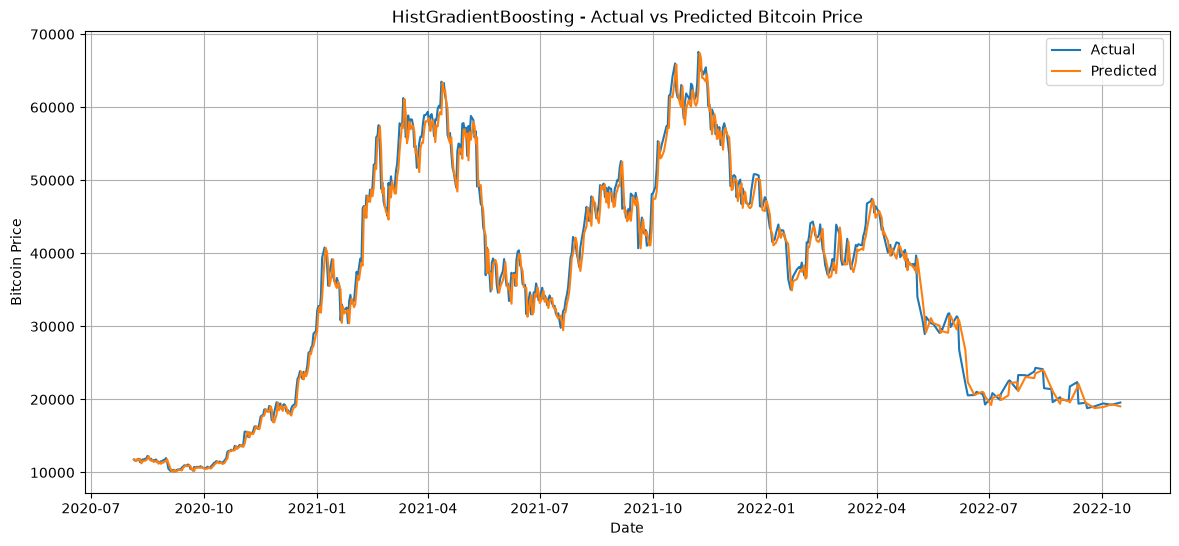

In [41]:
# Plot actual vs predicted prices

plt.figure(figsize=(14, 6))

plt.plot(
    final_hgb_results["Date"],
    final_hgb_results["Target"],
    label="Actual"
)

plt.plot(
    final_hgb_results["Date"],
    final_hgb_results["Predicted"],
    label="Predicted"
)

plt.title("HistGradientBoosting - Actual vs Predicted Bitcoin Price")
plt.xlabel("Date")
plt.ylabel("Bitcoin Price")
plt.legend()
plt.grid(True)

plt.savefig(
    "../outputs/graphs/12_hgb_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

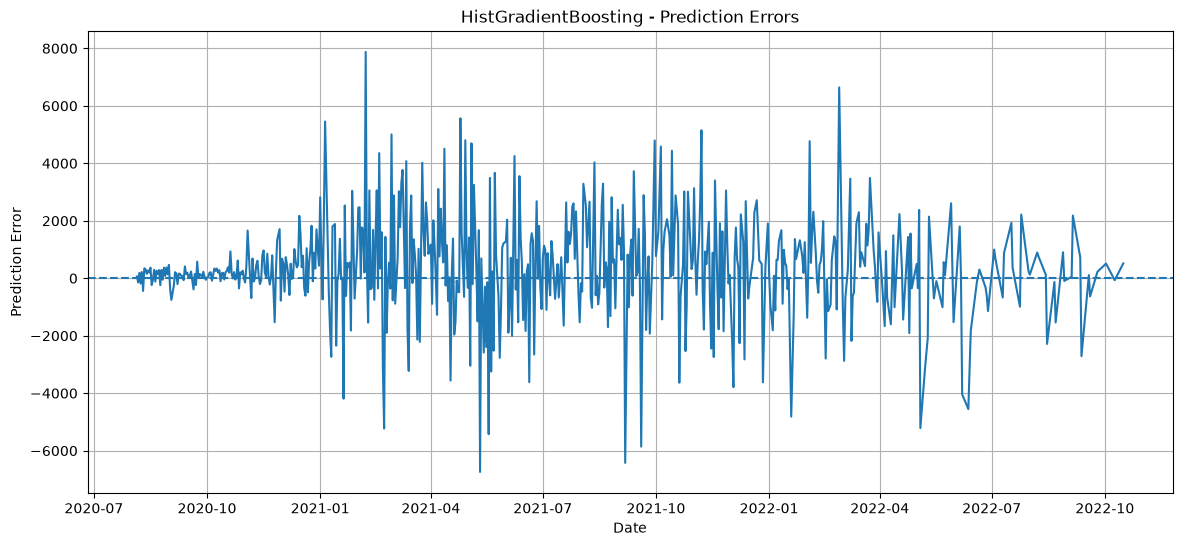

In [42]:
# Plot HGB prediction errors

plt.figure(figsize=(14, 6))

plt.plot(
    final_hgb_results["Date"],
    final_hgb_results["Error"]
)

plt.axhline(0, linestyle="--")

plt.title("HistGradientBoosting - Prediction Errors")
plt.xlabel("Date")
plt.ylabel("Prediction Error")
plt.grid(True)

plt.savefig(
    "../outputs/graphs/13_hgb_prediction_errors.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [43]:
# Calculate HGB feature importance

from sklearn.inspection import permutation_importance

feature_importance = permutation_importance(
    final_return_hgb_model,
    X_val,
    y_val_return,
    n_repeats=10,
    random_state=42,
    scoring="neg_mean_squared_error"
)

importance_df = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": feature_importance.importances_mean
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

print(importance_df)

          Feature  Importance
9          RSI_14    0.000075
8    Volatility_7    0.000056
10           MACD    0.000041
7          SMA_14    0.000038
4          Volume    0.000036
5          Return    0.000023
14          Lag_3    0.000018
11    MACD_Signal    0.000015
13          Lag_2    0.000011
0            Open    0.000009
2             Low    0.000008
6           SMA_7    0.000006
15  Volume_Change    0.000004
3           Close    0.000004
1            High    0.000002
12          Lag_1    0.000001


In [44]:
# Reset feature importance ranking

importance_df = importance_df.reset_index(drop=True)

importance_df.index = importance_df.index + 1

print(importance_df)

          Feature  Importance
1          RSI_14    0.000075
2    Volatility_7    0.000056
3            MACD    0.000041
4          SMA_14    0.000038
5          Volume    0.000036
6          Return    0.000023
7           Lag_3    0.000018
8     MACD_Signal    0.000015
9           Lag_2    0.000011
10           Open    0.000009
11            Low    0.000008
12          SMA_7    0.000006
13  Volume_Change    0.000004
14          Close    0.000004
15           High    0.000002
16          Lag_1    0.000001


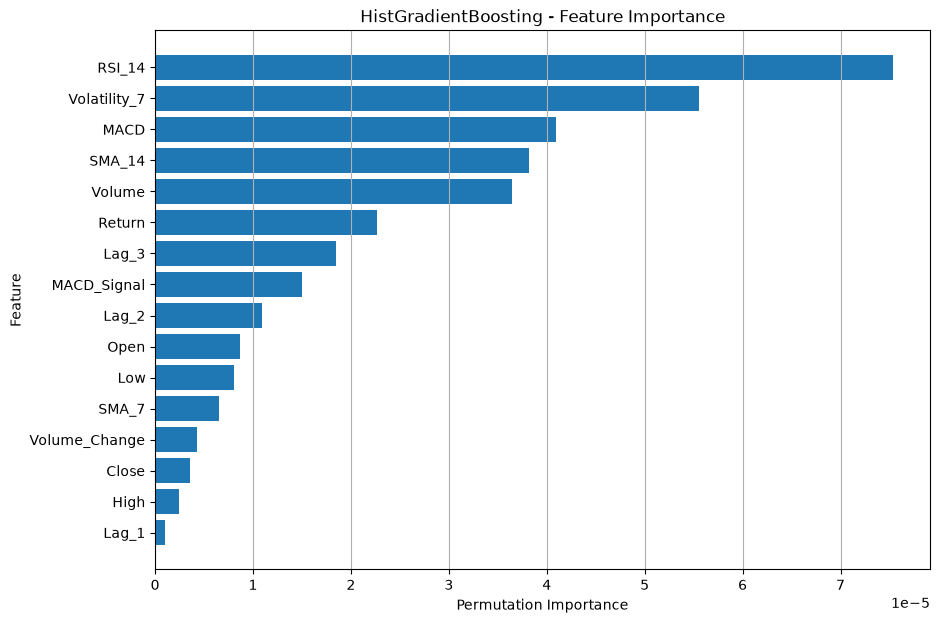

In [45]:
# Plot HGB feature importance

plt.figure(figsize=(10, 7))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.title("HistGradientBoosting - Feature Importance")
plt.xlabel("Permutation Importance")
plt.ylabel("Feature")
plt.gca().invert_yaxis()
plt.grid(axis="x")

plt.savefig(
    "../outputs/graphs/14_hgb_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [46]:
# Save final HGB model

import pickle

model_path = "../models/histgradientboosting_model.pkl"

with open(model_path, "wb") as file:
    pickle.dump(final_return_hgb_model, file)

print("Final HGB model saved successfully.")
print("Model path:", model_path)

Final HGB model saved successfully.
Model path: ../models/histgradientboosting_model.pkl


## Final HistGradientBoosting Model Summary

The HistGradientBoosting model was developed and evaluated through multiple stages to obtain a suitable forecasting approach for cryptocurrency price prediction.

### Modeling Process

- A baseline HistGradientBoosting model was initially trained to directly predict the target cryptocurrency price.
- The baseline model showed poor generalization to the unseen test period because Bitcoin prices increased substantially between the training and test periods.
- Hyperparameter tuning was initially performed using a chronological validation split.
- The absolute-price model still showed poor performance on the final test period.
- To improve generalization, the prediction target was reformulated as the next-period percentage return rather than the absolute cryptocurrency price.
- The predicted returns were converted back into cryptocurrency prices using the current closing price.
- The return-based model was then tuned using a chronological validation dataset while keeping the final test period untouched.
- The final model was retrained using the complete training dataset and evaluated on the unseen test period.

### Final Model Configuration

- Learning rate: 0.01
- Maximum iterations: 100
- Maximum leaf nodes: 31
- Minimum samples per leaf: 50
- L2 regularization: 0.0
- Random state: 42
- Prediction target: Next-period percentage return

### Final Test Performance

| Metric | Value |
|---|---:|
| MAE | 1237.20 |
| RMSE | 1765.01 |
| MAPE | 3.28% |
| R² | 0.9878 |

### Feature Importance

Permutation importance was used to interpret the contribution of the input features to return prediction.

The most influential features were:

1. RSI_14
2. Volatility_7
3. MACD
4. SMA_14
5. Volume

These results indicate that technical indicators and market activity features provide useful information for predicting short-term cryptocurrency price movements.

### Conclusion

The final return-based HistGradientBoosting model substantially improved upon the initial absolute-price model. Reformulating the prediction target as a percentage return helped the tree-based model handle the large changes in cryptocurrency price levels more effectively.

The final model achieved an R² of 0.9878 on the unseen test period, while the Actual vs Predicted graph shows that the predicted prices closely follow the observed Bitcoin price movement.